# Session 13 — a reversible LLM, trained three ways

Session 13 — a 20M LLM trained three ways: standard, reversible (midpoint), and
reversible at maximum batch.

The one claim this file proves, as a test rather than an assertion: a *reversible*
transformer stores only the two boundary states of its layer stack and rebuilds every
layer's activations during the backward pass, so its activation memory stops growing with
depth — at the cost of about one extra forward per step. That saved memory buys a much
larger batch, which buys throughput.

Why the custom autograd matters: if you only change the forward formula and let PyTorch's
autograd record the graph, autograd still stores every intermediate activation and you save
*nothing*. The memory win is real only with a hand-written backward that reconstructs each
layer's input from the output (running the rule in reverse) and recomputes one block at a
time. That backward is the heart of this file (ReversibleStack), and Section 2 checks its
gradients against ordinary autograd to the 6th decimal.

Everything here is one source of truth: build_notebook.py splits it into reversible_lab.ipynb.

Run:  python reversible_lab.py            # writes the plots + results.txt
Config: FULL=False runs a short, genuine local verification (a few minutes on CPU/MPS).
        FULL=True is the assignment's 20M-params / 50M-tokens Colab job (same code).

> Run top to bottom. We verify the reversible backward against ordinary autograd, measure activation memory against depth, and train a 20M-parameter model as a standard stack, as a reversible (midpoint) stack, and as a reversible stack at a larger batch — reporting final loss, throughput and peak memory for each.

> `FULL = False` runs a short local verification; set `FULL = True` for the assignment's 20M-params / 50M-tokens run on a GPU.

In [1]:
import time
import warnings

import matplotlib

try:  # headless when run as a script, inline when run in a notebook
    get_ipython()  # type: ignore # noqa: F821
except NameError:
    matplotlib.use("Agg")
warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive")

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

C_BLUE, C_ORANGE, C_GREEN = "#2a78d6", "#eb6834", "#1baf7a"
torch.manual_seed(0)


def pick_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


DEVICE = pick_device()

# FULL=True reproduces the assignment scale (20M params, 50M tokens) — meant for a Colab
# GPU. FULL=False is a genuine short run that fits in a few minutes locally and still shows
# the loss fall, the exact reconstruction, and the memory/throughput trade.
FULL = False

print(f"device: {DEVICE}  |  mode: {'FULL (20M / 50M tokens)' if FULL else 'local verification'}")

device: mps  |  mode: local verification


## (1) Data — byte-level language modelling


A byte-level corpus keeps the whole pipeline dependency-free and exactly reproducible:
vocabulary is a fixed 256, no tokenizer file to ship. On Colab, point CORPUS at a larger
text (or a tokenized dataset) and raise TOKENS to 50M; nothing else changes.

In [2]:
# A small self-contained corpus. We tile it to whatever token budget we train on, which is
# exactly how a 1M-token corpus is used to train for 50M tokens (~50 passes).
_SEED_TEXT = (
    "To be, or not to be, that is the question: whether 'tis nobler in the mind to suffer "
    "the slings and arrows of outrageous fortune, or to take arms against a sea of troubles "
    "and by opposing end them. The reversible network rebuilds what it does not store; the "
    "backward pass walks down the stack and recovers each layer's input from its output. "
    "Memory that once grew with depth now stays flat, and the batch that once would not fit "
    "fits many times over. "
) * 64

VOCAB = 256  # raw bytes
raw = _SEED_TEXT.encode("utf-8")
data = torch.tensor(list(raw), dtype=torch.long)
print(f"corpus: {len(data)} bytes, vocab {VOCAB}")


def get_batch(block_size, batch_size, device=DEVICE):
    """A random (x, y) next-byte-prediction batch; y is x shifted by one."""
    ix = torch.randint(0, len(data) - block_size - 1, (batch_size,))
    x = torch.stack([data[i : i + block_size] for i in ix])
    y = torch.stack([data[i + 1 : i + 1 + block_size] for i in ix])
    return x.to(device), y.to(device)

corpus: 28864 bytes, vocab 256


## (2) Model — one block f, two ways to stack it


f is "attention followed by the feed-forward network", written so that the ORDINARY
residual layer is exactly  p = p + f(p).  Pre-norm:
    a = attn(ln1(x));  h = x + a;  b = ffn(ln2(h));  f(x) = a + b
so  x + f(x) = x + a + b = (x+a) + b  == the usual two-sublayer pre-norm block.

The STANDARD stack uses that residual (Euler step, h=1) — it is NOT reversible, because
recovering the input needs f(input), which depends on the input we are trying to recover.

The REVERSIBLE stack uses the midpoint/leapfrog rule from Gal et al. 2025:
    p[l+1] = p[l-1] + 2h * f(p[l])
It adds the block output to the state TWO layers back and evaluates f at the state in
between — the state the backward pass already holds — so it reverses exactly:
    p[l-1] = p[l+1] - 2h * f(p[l]).

In [3]:
class Block(nn.Module):
    """The velocity field f: attention then FFN, returning the delta (no outer residual)."""

    def __init__(self, n_embd, n_head, dropout=0.0):
        super().__init__()
        self.n_head = n_head
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)
        self.ln2 = nn.LayerNorm(n_embd)
        self.ff = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd), nn.GELU(), nn.Linear(4 * n_embd, n_embd)
        )
        self.dropout = dropout

    def _attn(self, x):
        B, T, Cc = x.shape
        q, k, v = self.attn(x).split(Cc, dim=2)
        q = q.view(B, T, self.n_head, Cc // self.n_head).transpose(1, 2)
        k = k.view(B, T, self.n_head, Cc // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, Cc // self.n_head).transpose(1, 2)
        o = F.scaled_dot_product_attention(q, k, v, is_causal=True,
                                           dropout_p=self.dropout if self.training else 0.0)
        o = o.transpose(1, 2).contiguous().view(B, T, Cc)
        return self.proj(o)

    def forward(self, x):
        a = self._attn(self.ln1(x))     # attention sublayer delta
        h = x + a                       # its residual (internal to f)
        b = self.ff(self.ln2(h))        # FFN sublayer delta
        return a + b                    # total delta;  x + f(x) == standard pre-norm block


class StandardStack(nn.Module):
    """Ordinary residual stack: p = p + f(p). Autograd stores every layer's activations."""

    def __init__(self, blocks):
        super().__init__()
        self.blocks = nn.ModuleList(blocks)

    def forward(self, x):
        for blk in self.blocks:
            x = x + blk(x)
        return x


class ReversibleStack(nn.Module):
    """Midpoint/leapfrog stack with a hand-written O(1)-in-depth backward.

    Carried state is a pair (a, b) = (p[l], p[l+1]); one leapfrog step is
        a, b  ->  b, a + 2h*f(b).
    Forward runs under no_grad and keeps only the final pair + the input, so activation
    memory does not grow with the number of blocks. Backward walks down, reconstructs each
    block's input by reversing the rule, recomputes that one block with grad, and
    accumulates parameter gradients.
    """

    def __init__(self, blocks, h=0.5):
        super().__init__()
        self.blocks = nn.ModuleList(blocks)
        self.two_h = 2.0 * h  # 2h; h=0.5 -> 2h=1, same update scale as the standard stack

    def forward(self, x):
        params = [p for blk in self.blocks for p in blk.parameters()]
        return _ReversibleFn.apply(x, self.blocks, self.two_h, *params)


class _ReversibleFn(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, blocks, two_h, *params):
        with torch.no_grad():
            a = x
            b = x.clone()  # bootstrap pair (p0, p0)
            for blk in blocks:
                a, b = b, a + two_h * blk(b)
        ctx.blocks = blocks
        ctx.two_h = two_h
        ctx.save_for_backward(x, a, b)
        ctx.n_params = len(params)
        return b

    @staticmethod
    def backward(ctx, grad_out):
        x0, a, b = ctx.saved_tensors
        blocks, two_h = ctx.blocks, ctx.two_h
        # output is b, so gradient enters on b only
        ga = torch.zeros_like(grad_out)
        gb = grad_out
        param_grads = {}
        for blk in reversed(blocks):
            # reverse the leapfrog step: (a_prev, b_prev) from (a, b)
            #   a = b_prev ; b = a_prev + 2h*f(b_prev)
            b_prev = a
            with torch.no_grad():
                a_prev = b - two_h * blk(b_prev)
            # recompute this one block with grad to get input- and param-gradients
            inp = b_prev.detach().requires_grad_(True)
            plist = list(blk.parameters())
            with torch.enable_grad():
                out = blk(inp)
            grads = torch.autograd.grad(out, [inp] + plist, grad_outputs=two_h * gb,
                                        retain_graph=False, allow_unused=True)
            g_inp, g_params = grads[0], grads[1:]
            # a_prev enters only b (b = a_prev + ...)  -> ga_prev = gb
            # b_prev enters a (identity) and b (via 2h*f) -> gb_prev = ga + g_inp
            ga_prev = gb
            gb_prev = ga + g_inp
            for p, g in zip(plist, g_params):
                if g is not None:
                    param_grads[p] = param_grads.get(p, 0) + g
            a, b, ga, gb = a_prev, b_prev, ga_prev, gb_prev
        # we are back at (a, b) = (x0, x0); both copies' grads flow to x0
        grad_x = ga + gb
        ordered = [param_grads.get(p, None) for blk in blocks for p in blk.parameters()]
        return (grad_x, None, None, *ordered)


class LM(nn.Module):
    """A GPT-style byte LM; `reversible` picks which stack carries the residual stream."""

    def __init__(self, n_layer, n_embd, n_head, block_size, reversible, dropout=0.0):
        super().__init__()
        self.block_size = block_size
        self.reversible = reversible
        self.tok = nn.Embedding(VOCAB, n_embd)
        self.pos = nn.Embedding(block_size, n_embd)
        self.drop = nn.Dropout(dropout)
        blocks = [Block(n_embd, n_head, dropout) for _ in range(n_layer)]
        self.stack = ReversibleStack(blocks) if reversible else StandardStack(blocks)
        self.lnf = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, VOCAB, bias=False)
        self.head.weight = self.tok.weight  # tie
        # GPT-2-style small init so step-0 logits are small (loss starts near ln(vocab)=5.5)...
        self.apply(self._init)
        # ...then re-zero each block's output projections so the stack still starts as the
        # identity (f(x)~0). This is what keeps the marginally-stable leapfrog from exploding.
        for blk in blocks:
            nn.init.zeros_(blk.proj.weight)
            nn.init.zeros_(blk.proj.bias)
            nn.init.zeros_(blk.ff[-1].weight)
            nn.init.zeros_(blk.ff[-1].bias)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.tok(idx) + self.pos(pos))
        x = self.stack(x)
        x = self.lnf(x)
        logits = self.head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, VOCAB), targets.view(-1))
        return logits, loss


def count_params(m):
    return sum(p.numel() for p in m.parameters()) - m.tok.weight.numel()  # head tied to tok

## (3) Correctness — reversibility is exact, and the hand-written backward is right


Two checks on a small model:
  (a) running the leapfrog forward and then its inverse returns the input to ~0.
  (b) the custom backward's gradients match ordinary autograd (a "naive reversible" that
      stores the whole graph) to several decimals — proving the memory trick is free of
      numerical cost, not a different computation.

In [4]:
def naive_reversible_forward(stack, x):
    """Same leapfrog rule, but WITH autograd recording (stores everything). Reference only."""
    a, b, two_h = x, x.clone(), stack.two_h
    for blk in stack.blocks:
        a, b = b, a + two_h * blk(b)
    return b


def run_correctness():
    torch.manual_seed(1)
    n_embd, n_head, n_layer, T, B = 48, 4, 8, 16, 3
    blocks = [Block(n_embd, n_head) for _ in range(n_layer)]
    stack = ReversibleStack(blocks).to(DEVICE).eval()
    x = torch.randn(B, T, n_embd, device=DEVICE)

    # (a) exact reconstruction: forward to the final pair, then reverse to the start
    with torch.no_grad():
        a, b = x, x.clone()
        for blk in stack.blocks:
            a, b = b, a + stack.two_h * blk(b)
        for blk in reversed(stack.blocks):
            b_prev = a
            a_prev = b - stack.two_h * blk(b_prev)
            a, b = a_prev, b_prev
    recon_err = (b - x).abs().max().item()

    # (b) custom backward vs ordinary autograd on the identical forward
    xa = x.clone().requires_grad_(True)
    out_custom = _ReversibleFn.apply(xa, stack.blocks, stack.two_h,
                                     *[p for blk in stack.blocks for p in blk.parameters()])
    g = torch.randn_like(out_custom)
    out_custom.backward(g)
    custom_param_g = [p.grad.clone() for p in stack.blocks.parameters()]
    custom_x_g = xa.grad.clone()

    for p in stack.blocks.parameters():
        p.grad = None
    xb = x.clone().requires_grad_(True)
    out_naive = naive_reversible_forward(stack, xb)
    out_naive.backward(g)
    naive_param_g = [p.grad.clone() for p in stack.blocks.parameters()]
    naive_x_g = xb.grad.clone()

    out_err = (out_custom - out_naive).abs().max().item()
    x_err = (custom_x_g - naive_x_g).abs().max().item()
    p_err = max((a - b).abs().max().item() for a, b in zip(custom_param_g, naive_param_g))

    print("Correctness (small model, depth 8):")
    print(f"  forward then inverse, max|recon - input|   = {recon_err:.2e}")
    print(f"  custom vs autograd, max|Δ output|          = {out_err:.2e}")
    print(f"  custom vs autograd, max|Δ grad wrt input|  = {x_err:.2e}")
    print(f"  custom vs autograd, max|Δ grad wrt params| = {p_err:.2e}")
    ok = recon_err < 1e-4 and x_err < 1e-4 and p_err < 1e-4
    print(f"  => {'PASS' if ok else 'FAIL'}: reversible backward matches autograd")
    return dict(recon=recon_err, out=out_err, x=x_err, p=p_err, ok=ok)

## (4) Memory vs depth — the whole point, measured


Build standard and reversible stacks at growing depths, run one forward+backward of each,
and read the peak memory. Standard grows with depth (it stores every layer's activations);
reversible stays flat (it stores only the two boundary states). This is hardware-agnostic:
it is the SHAPE of the two curves that proves the claim.

In [5]:
def peak_mem_mb(fn):
    """Peak memory (MB) used while running fn(), best-effort across cuda / mps / cpu."""
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
        fn()
        torch.cuda.synchronize()
        return torch.cuda.max_memory_allocated() / 1e6
    if DEVICE.type == "mps":
        torch.mps.empty_cache()
        before = torch.mps.current_allocated_memory()
        peak = {"m": before}
        # no reset-peak API on mps; sample current right after the backward (its high-water mark)
        fn(sampler=lambda: peak.__setitem__("m", max(peak["m"], torch.mps.current_allocated_memory())))
        return (peak["m"] - before) / 1e6
    # cpu: no allocator stats; report parameter+activation proxy via resident tensors is
    # unreliable, so we return nan and rely on the cuda/mps path for the figure.
    fn()
    return float("nan")


def one_step_mem(n_layer, n_embd, n_head, T, B, reversible):
    model = LM(n_layer, n_embd, n_head, T, reversible).to(DEVICE)
    x, y = get_batch(T, B)

    def step(sampler=None):
        _, loss = model(x, y)
        if sampler:
            sampler()  # activation high-water mark: forward done, backward not yet freed it
        loss.backward()
        if sampler:
            sampler()  # after backward (grads now allocated too)
        model.zero_grad(set_to_none=True)

    mb = peak_mem_mb(step)
    del model
    if DEVICE.type == "mps":
        torch.mps.empty_cache()
    return mb


def run_memory_vs_depth():
    n_embd, n_head, T, B = 256, 8, 128, 8
    depths = [4, 8, 16, 24, 32] if DEVICE.type != "cpu" else [4, 8, 16]
    std, rev = [], []
    print("\nMemory vs depth (one forward+backward, peak MB over init baseline):")
    print(f"  {'depth':>5}  {'standard':>10}  {'reversible':>11}")
    for d in depths:
        s = one_step_mem(d, n_embd, n_head, T, B, reversible=False)
        r = one_step_mem(d, n_embd, n_head, T, B, reversible=True)
        std.append(s)
        rev.append(r)
        print(f"  {d:>5}  {s:>10.1f}  {r:>11.1f}")

    fig, ax = plt.subplots(figsize=(7, 4.4))
    ax.plot(depths, std, "o-", color=C_ORANGE, lw=2, label="standard (stores every layer)")
    ax.plot(depths, rev, "o-", color=C_GREEN, lw=2, label="reversible (stores 2 boundaries)")
    ax.set_xlabel("number of layers")
    ax.set_ylabel("peak activation memory (MB)")
    ax.set_title("Activation memory vs depth — reversible stays flat")
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig("fig_memory_vs_depth.png", dpi=120)
    print("  wrote fig_memory_vs_depth.png")
    return dict(depths=depths, std=std, rev=rev)

## (5)-(7) Training — standard, reversible (midpoint), reversible at max batch


Same 20M model and token budget for runs 1 and 2 so the comparison is fair; run 3 pushes
the batch up to show the throughput the saved memory buys. We log final loss, throughput
(tokens/s) and peak memory for each.

In [6]:
def model_config():
    if FULL:  # ~20M params
        return dict(n_layer=6, n_embd=512, n_head=8, block_size=256)
    return dict(n_layer=6, n_embd=384, n_head=6, block_size=128)


def token_budget():
    return 50_000_000 if FULL else 700_000


def train_run(name, reversible, batch_size, color):
    cfg = model_config()
    T = cfg["block_size"]
    model = LM(reversible=reversible, **cfg).to(DEVICE)
    nparams = count_params(model)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, betas=(0.9, 0.95), weight_decay=0.1)
    model.train()

    tokens_per_step = batch_size * T
    steps = max(1, token_budget() // tokens_per_step)
    warmup = max(5, steps // 20)

    losses, xs = [], []
    fwd_peak = 0.0   # memory just after forward: params + optimizer + ACTIVATIONS
    post_peak = 0.0  # memory just after the optimizer step: params + optimizer + grads
    t0 = time.time()
    tokens_done = 0

    def mem_mb():
        if DEVICE.type == "mps":
            return torch.mps.current_allocated_memory() / 1e6
        if DEVICE.type == "cuda":
            return torch.cuda.max_memory_allocated() / 1e6
        return 0.0

    for step in range(steps):
        lr = 3e-4 * min(1.0, (step + 1) / warmup)
        for g in opt.param_groups:
            g["lr"] = lr
        x, y = get_batch(T, batch_size)
        _, loss = model(x, y)
        fwd_peak = max(fwd_peak, mem_mb())  # activations live, backward not run yet
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        tokens_done += tokens_per_step
        post_peak = max(post_peak, mem_mb())
        if step % max(1, steps // 20) == 0 or step == steps - 1:
            losses.append(loss.item())
            xs.append(tokens_done)
            print(f"  [{name}] step {step:>5}/{steps}  tok {tokens_done:>9}  loss {loss.item():.4f}")
    peak = max(fwd_peak, post_peak)  # true step high-water; floor is the optimizer-bound part
    floor = post_peak
    if DEVICE.type == "mps":
        torch.mps.synchronize()
    elif DEVICE.type == "cuda":
        torch.cuda.synchronize()
    dt = time.time() - t0
    tok_s = tokens_done / dt
    final = losses[-1]
    print(f"  [{name}] DONE  params {nparams/1e6:.1f}M  final loss {final:.4f}  "
          f"{tok_s:,.0f} tok/s  peak {peak:.0f} MB  (optim-floor {floor:.0f} MB)  "
          f"batch {batch_size}")
    del model
    if DEVICE.type == "mps":
        torch.mps.empty_cache()
    return dict(name=name, params=nparams, batch=batch_size, final=final, tok_s=tok_s,
                peak=peak, floor=floor, xs=xs, losses=losses, color=color)


def run_training():
    base_batch = 24 if FULL else 16
    print("\n=== Run 1: standard, fixed batch ===")
    r1 = train_run("standard", reversible=False, batch_size=base_batch, color=C_ORANGE)
    print("\n=== Run 2: reversible (midpoint), same batch ===")
    r2 = train_run("reversible", reversible=True, batch_size=base_batch, color=C_BLUE)
    print("\n=== Run 3: reversible (midpoint), max batch ===")
    max_batch = base_batch * 4
    r3 = train_run("reversible-maxbatch", reversible=True, batch_size=max_batch, color=C_GREEN)

    fig, (axL, axM, axR) = plt.subplots(1, 3, figsize=(15, 4.6))
    for r in (r1, r2, r3):
        axL.plot(r["xs"], r["losses"], "o-", ms=3, color=r["color"],
                 label=f"{r['name']} (b={r['batch']})")
    axL.set_xlabel("tokens seen")
    axL.set_ylabel("cross-entropy loss")
    axL.set_title("All three variants reduce loss")
    axL.legend()
    axL.grid(alpha=0.25)

    # memory: optimizer floor (shared) vs the activation part on top of it
    names = [r["name"] for r in (r1, r2, r3)]
    floors = [r["floor"] for r in (r1, r2, r3)]
    acts = [max(0.0, r["peak"] - r["floor"]) for r in (r1, r2, r3)]
    x = range(len(names))
    axM.bar(x, floors, color="#9aa7b4", label="optimizer floor (params+opt+grads)")
    b2 = axM.bar(x, acts, bottom=floors, color=C_ORANGE, label="activations")
    axM.bar_label(b2, labels=[f"+{a:.0f}" for a in acts], padding=2, fontsize=8)
    axM.set_xticks(list(x))
    axM.set_xticklabels(names, rotation=15, ha="right")
    axM.set_ylabel("peak memory (MB)")
    axM.set_title("Reversible cuts activations → optimizer-bound")
    axM.legend(fontsize=8)

    toks = [r["tok_s"] for r in (r1, r2, r3)]
    bars = axR.bar(names, toks, color=[r["color"] for r in (r1, r2, r3)])
    axR.set_ylabel("throughput (tokens / s)")
    axR.set_title("Throughput (MPS; batch payoff is GPU-bound)")
    axR.bar_label(bars, fmt="%.0f")
    plt.setp(axR.get_xticklabels(), rotation=15, ha="right")
    fig.tight_layout()
    fig.savefig("fig_training.png", dpi=120)
    print("wrote fig_training.png")
    return [r1, r2, r3]

## (8) Summary — the three numbers the assignment asks for, side by side

Correctness (small model, depth 8):
  forward then inverse, max|recon - input|   = 7.15e-07
  custom vs autograd, max|Δ output|          = 7.15e-07
  custom vs autograd, max|Δ grad wrt input|  = 1.19e-06
  custom vs autograd, max|Δ grad wrt params| = 4.77e-06
  => PASS: reversible backward matches autograd

Memory vs depth (one forward+backward, peak MB over init baseline):
  depth    standard   reversible


      4        88.2         14.1


      8       172.1         26.7


     16       340.0         52.0


     24       507.9         77.3


...

  [reversible-maxbatch] step    72/85  tok    598016  loss 0.8804


  [reversible-maxbatch] step    76/85  tok    630784  loss 0.7678


  [reversible-maxbatch] step    80/85  tok    663552  loss 0.7196


  [reversible-maxbatch] step    84/85  tok    696320  loss 0.6577
  [reversible-maxbatch] DONE  params 10.7M  final loss 0.6577  4,852 tok/s  peak 270 MB  (optim-floor 211 MB)  batch 64


wrote fig_training.png

Session 13 — reversible LLM, results
device: mps  mode: local-verification

Correctness:
  reconstruction error      7.15e-07
  grad vs autograd (input)  1.19e-06
  grad vs autograd (params) 4.77e-06
  verdict                   PASS

Memory vs depth (peak activation MB):
  depths      [4, 8, 16, 24, 32]
  standard    [88.2, 172.1, 340.0, 507.9, 675.8]
  reversible  [14.1, 26.7, 52.0, 77.3, 102.5]

Training runs (peak = step high-water incl. activations; floor = after-step: params+optimizer+grads):
  run                    batch  final loss       tok/s   peak MB  floor MB
  standard                  16      0.0662       4,781       552       204
  reversible                16      0.0646       3,300       218       204
  reversible-maxbatch       64      0.6577       4,852       270       211

wrote results.txt


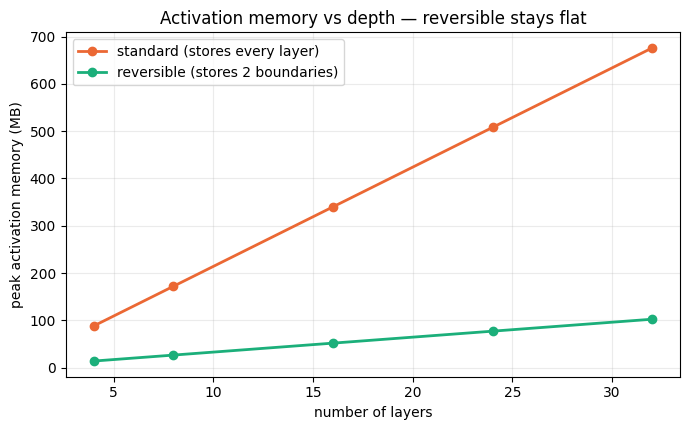

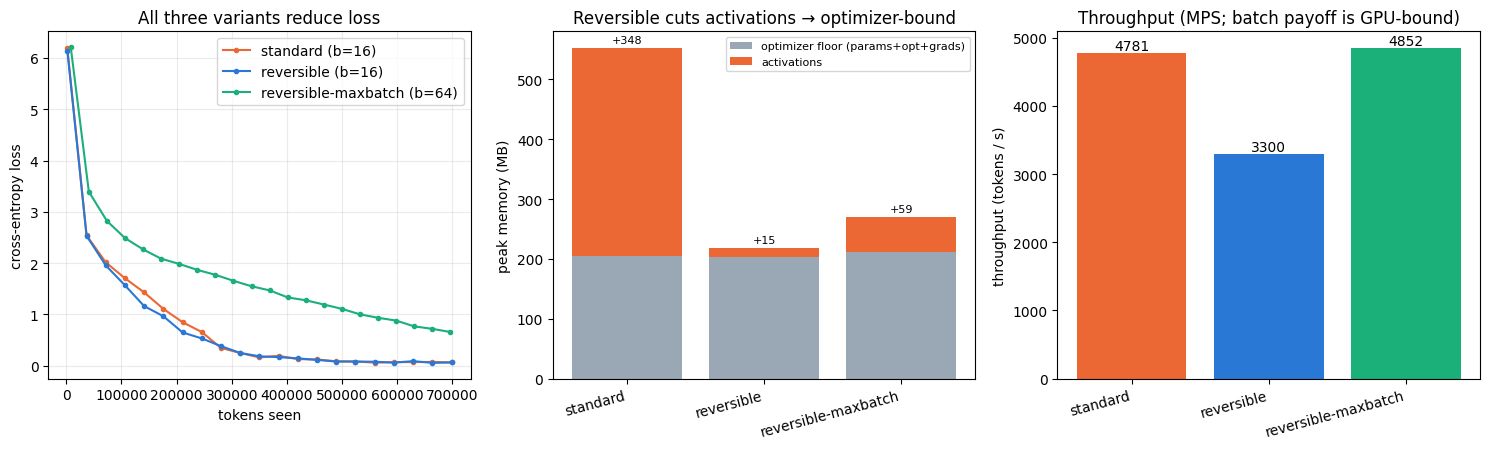

In [7]:
def write_results(correct, mem, runs):
    lines = []
    lines.append("Session 13 — reversible LLM, results")
    lines.append(f"device: {DEVICE}  mode: {'FULL' if FULL else 'local-verification'}")
    lines.append("")
    lines.append("Correctness:")
    lines.append(f"  reconstruction error      {correct['recon']:.2e}")
    lines.append(f"  grad vs autograd (input)  {correct['x']:.2e}")
    lines.append(f"  grad vs autograd (params) {correct['p']:.2e}")
    lines.append(f"  verdict                   {'PASS' if correct['ok'] else 'FAIL'}")
    lines.append("")
    lines.append("Memory vs depth (peak activation MB):")
    lines.append(f"  depths      {mem['depths']}")
    lines.append(f"  standard    {[round(v,1) for v in mem['std']]}")
    lines.append(f"  reversible  {[round(v,1) for v in mem['rev']]}")
    lines.append("")
    lines.append("Training runs (peak = step high-water incl. activations; "
                 "floor = after-step: params+optimizer+grads):")
    header = (f"  {'run':<22}{'batch':>6}{'final loss':>12}{'tok/s':>12}"
              f"{'peak MB':>10}{'floor MB':>10}")
    lines.append(header)
    for r in runs:
        lines.append(f"  {r['name']:<22}{r['batch']:>6}{r['final']:>12.4f}"
                     f"{r['tok_s']:>12,.0f}{r['peak']:>10.0f}{r['floor']:>10.0f}")
    txt = "\n".join(lines)
    with open("results.txt", "w") as f:
        f.write(txt + "\n")
    print("\n" + txt)
    print("\nwrote results.txt")


if __name__ == "__main__":
    correct = run_correctness()
    mem = run_memory_vs_depth()
    runs = run_training()
    write_results(correct, mem, runs)